# BÀI KIỂM TRA 3 – TỐI ƯU HÓA, CẢI TIẾN & SO SÁNH MÔ HÌNH
**Đề tài:** Phân tích giỏ hàng và phát hiện các sản phẩm thường được mua kèm

**Nhóm 23 (CNTT K22H – ICTU):** Trần Văn Thực (`DTC235200734`), Nguyễn Đức An Bình (`DTC235200066`)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from src.data_pipeline import load_raw_baskets, prepare_dataset
from src.algorithms import mine_with_metrics, evaluate_rules_on_test
from src.part3_experiments import run_cv_grid_search, run_ablation_study, prune_redundant_rules

bundle = prepare_dataset(load_raw_baskets(), min_basket_size=2, test_size=0.20, random_state=42)
print(f'Tập phát triển (Train 80%): {len(bundle.train_baskets):,} giỏ | Tập kiểm tra (Test 20%): {len(bundle.test_baskets):,} giỏ')

Tập phát triển (Train 80%): 6,140 giỏ | Tập kiểm tra (Test 20%): 1,536 giỏ


## 1. Tối ưu hóa siêu tham số bằng Grid Search trên 5-Fold CV (chỉ trên tập Train)

In [2]:
grid_df = run_cv_grid_search(
    bundle.train_baskets,
    support_grid=[0.005, 0.008, 0.010, 0.015],
    confidence_grid=[0.20, 0.25, 0.30],
    lift_grid=[1.30, 1.50, 1.80],
    max_len_grid=[2, 3, None],
    n_splits=5,
)
print('Top 10 cấu hình trên 5-Fold CV:')
grid_df.head(10)

Top 10 cấu hình trên 5-Fold CV:


,min_support,min_confidence,min_lift,max_len,n_rules_mean,n_rules_std,train_lift_mean,train_conf_mean,val_lift_mean,val_lift_std,val_conf_mean,val_conf_std,rule_retention_pct
0,0.005,0.20,1.8,None,806.6,58.183331,2.488510,0.392819,2.207771,0.124714,0.352156,0.015007,99.896144
1,0.005,0.25,1.8,None,642.2,44.200679,2.452649,0.436691,2.187547,0.116200,0.392958,0.015159,99.935587
2,0.005,0.30,1.8,None,512.4,34.810918,2.419846,0.478335,2.148836,0.099591,0.428932,0.014971,99.918263
3,0.005,0.25,1.8,2,37.6,3.361547,2.376082,0.364224,2.114187,0.091927,0.320988,0.011751,100.000000
4,0.008,0.20,1.8,None,230.6,18.902381,2.262460,0.377091,2.069115,0.113260,0.346220,0.013997,100.000000
5,0.010,0.25,1.8,None,104.0,6.204837,2.162460,0.400876,2.066262,0.096097,0.380146,0.009174,100.000000
6,0.008,0.25,1.8,None,187.0,12.020815,2.232892,0.413576,2.062378,0.105910,0.381969,0.011852,100.000000
7,0.010,0.20,1.8,None,124.2,6.496153,2.171335,0.371212,2.059584,0.094147,0.350674,0.010294,100.000000
8,0.008,0.30,1.8,None,146.4,12.934450,2.234584,0.452735,2.044330,0.084159,0.415366,0.012356,100.000000
9,0.010,0.30,1.8,None,77.4,6.348228,2.164265,0.444686,2.042204,0.070683,0.417694,0.009663,100.000000


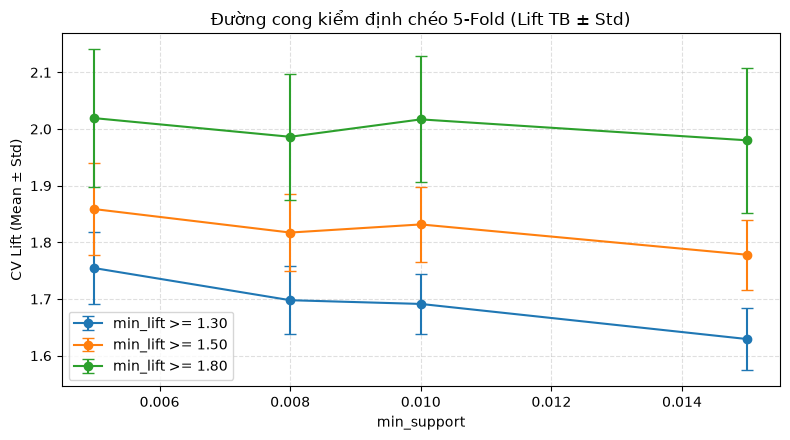

In [3]:
sub_grid = grid_df[(grid_df['min_confidence'] == 0.25) & (grid_df['max_len'] == 3)]
fig, ax = plt.subplots(figsize=(8, 4.5))
for l_val in sorted(sub_grid['min_lift'].unique()):
    s = sub_grid[sub_grid['min_lift'] == l_val].sort_values('min_support')
    ax.errorbar(s['min_support'], s['val_lift_mean'], yerr=s['val_lift_std'], marker='o', capsize=4, label=f'min_lift >= {l_val:.2f}')
ax.set_title('Đường cong kiểm định chéo 5-Fold (Lift TB ± Std)')
ax.set_xlabel('min_support')
ax.set_ylabel('CV Lift (Mean ± Std)')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

## 2. Nghiên cứu đóng góp từng bước cải tiến (Ablation Study: 5-Fold CV vs Test 20%)

In [4]:
ablation_df = run_ablation_study(
    raw_clean_baskets=bundle.clean_baskets,
    filtered_train_baskets=bundle.train_baskets,
    df_filtered_train=bundle.df_train,
    df_filtered_test=bundle.df_test,
)
ablation_df

,step,n_rules_train,cv_lift_mean,cv_lift_std,cv_conf_mean,cv_conf_std,test_lift,test_conf,delta_cv_lift
0,0. Mô hình cơ sở (Most Popular: whole milk),1,1.000000,0.000000,31.514658,0.000000,1.000000,29.752604,0.000000
1,"1. FP-Growth ban đầu (dữ liệu thô, Lift≥1.30)",286,1.897467,0.105624,36.283494,1.748560,2.032648,36.790658,0.897467
2,2. + Lọc giỏ hàng < 2 món (giảm nhiễu đơn lẻ),406,1.751479,0.058258,38.463855,1.093799,1.696628,34.712199,-0.145988
3,"3. + Tối ưu siêu tham số (Lift≥1.50, max_len=3)",270,1.817287,0.068730,38.938992,1.053600,1.787662,34.976946,0.065808
4,4. + Hậu xử lý cắt tỉa luật dư thừa (Pruning),266,1.816155,0.067329,38.914822,0.961607,1.784488,35.070376,-0.001132


## 3. Đánh giá mô hình cuối cùng (sau tối ưu & cắt tỉa luật dư thừa) trên tập Test giữ lại

In [5]:
final_res = mine_with_metrics(bundle.df_train, algorithm='FP-Growth (mlxtend)', min_support=0.008, min_confidence=0.25, min_lift=1.50, max_len=3)
pruned_rules = prune_redundant_rules(final_res.rules)
eval_final = evaluate_rules_on_test(pruned_rules, bundle.df_test)
print(f'Số luật trước Pruning: {len(final_res.rules)} -> Sau Pruning: {len(pruned_rules)}')
print(f"Train Lift TB: {pruned_rules['lift'].mean():.3f} | Test Lift TB: {eval_final['test_lift'].mean():.3f}")
print(f"Train Conf TB: {pruned_rules['confidence'].mean()*100:.2f}% | Test Conf TB: {eval_final['test_confidence'].mean()*100:.2f}%")
eval_final.head(10)

Số luật trước Pruning: 270 -> Sau Pruning: 266
Train Lift TB: 1.920 | Test Lift TB: 1.784
Train Conf TB: 41.37% | Test Conf TB: 35.07%


,rule,train_support,test_support,train_confidence,test_confidence,train_lift,test_lift,conviction
0,"butter, other vegetables -> whipped/sour cream",0.008143,0.004557,0.306748,0.205882,3.412021,2.490042,1.312796
1,herbs -> root vegetables,0.009121,0.008464,0.466667,0.351351,3.331783,2.885966,1.612378
2,berries -> whipped/sour cream,0.011889,0.010417,0.274436,0.313725,3.052604,3.794349,1.254332
3,"other vegetables, tropical fruit -> pip fruit",0.013029,0.008464,0.281690,0.188406,2.941458,2.260870,1.258836
4,"other vegetables, pip fruit -> tropical fruit",0.013029,0.008464,0.382775,0.270833,2.883729,2.144330,1.405102
5,"beef, other vegetables -> root vegetables",0.010749,0.007812,0.395210,0.444444,2.821613,3.650624,1.421872
6,"root vegetables, yogurt -> whipped/sour cream",0.008795,0.005859,0.252336,0.225000,2.806786,2.721260,1.217256
7,"pip fruit, yogurt -> tropical fruit",0.008958,0.005208,0.369128,0.285714,2.780912,2.262150,1.374705
8,"citrus fruit, other vegetables -> root vegetables",0.014332,0.009115,0.379310,0.269231,2.708099,2.211436,1.385451
9,"other vegetables, tropical fruit -> citrus fruit",0.012866,0.006510,0.278169,0.144928,2.677050,1.391304,1.241414
